# 19B — Clean Spatial / Wind Ablation
## Does spatial information add beyond the strong local baseline?

Notebook 19 showed that:

- `LR13` local current fire + local fire history is already very strong;
- same-cell weather did not improve ranking;
- generic spatial features slightly recovered performance relative to the weather model;
- wind-aware features did not improve the cumulative model.

However, that cumulative sequence did **not** answer the cleanest question:

> Does spatial information add predictive information **directly beyond LR13**?

This notebook therefore performs a clean ablation with the same T2 regional domain,
same August validation period, and September still **SEALED**.

### Primary comparison

```text
LR13
local current fire + local fire history

LR17-G
LR13 + generic neighboring fire activity

LR17-W
LR13 + wind-aligned neighboring fire activity

LR21-GW
LR13 + generic spatial + wind-aware spatial

LR23-WX
LR13 + same-cell weather
(reference only)
```

### Main questions

1. Does generic spatial information improve over LR13?
2. Does wind-aware spatial information improve over LR13?
3. Does wind add anything beyond generic spatial information?
4. Are any gains concentrated in Emerging-3 cases rather than persistent cases?

### Evaluation discipline

- Train: May–July 2026
- Validation: August 2026
- September: **SEALED**
- Primary spatial radius: **75 km**
- 50 km and 100 km: sensitivity only, not used to cherry-pick the final model
- Primary metric: PR-AUC
- Emerging-3 is evaluated on all rows with no local detection in `t-2:t`

Wind-aware features remain **associative transport-aware predictors**, not proof of
causal fire spread.

In [2]:
# 1. Imports

from pathlib import Path
import sys
import json
import importlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 240)

RANDOM_STATE = 42
PRIMARY_RADIUS_KM = 75.0
SENSITIVITY_RADII_KM = [50.0, 75.0, 100.0]
RUN_TEST = False

In [3]:
# 2. Resolve project root and Notebook 17 V2 metadata

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    candidate = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )
    if candidate.exists():
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the regional 0.25° dataset. "
        "Open VS Code at the skripsi-karhut project root or set PROJECT_ROOT manually."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

NODE_PATH = (
    PROJECT_ROOT
    / "data"
    / "intermediate"
    / "regional_025"
    / "regional_grid_nodes_025.csv"
)

NB17_EXPORT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_dataset"
    / "exports"
)

LOCK_PATH = (
    NB17_EXPORT_DIR
    / "regional_domain_lock_train_only.json"
)

METHODOLOGY_PATH = (
    NB17_EXPORT_DIR
    / "regional_025_methodology_metadata.json"
)

for required_path in [
    DATA_PATH,
    NODE_PATH,
    LOCK_PATH,
    METHODOLOGY_PATH,
]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required Notebook 17 V2 artifact is missing: {required_path}"
        )

lock_metadata = json.loads(
    LOCK_PATH.read_text(encoding="utf-8")
)

methodology_metadata = json.loads(
    METHODOLOGY_PATH.read_text(encoding="utf-8")
)

LOCKED_REGION_ID = str(
    lock_metadata["candidate_id"]
)

EXPECTED_NODES = int(
    methodology_metadata["weather"]["requested_grid_centers"]
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_spatial_wind_ablation"
    / LOCKED_REGION_ID.lower()
)

FIGURES_DIR = RESULTS_DIR / "figures"
EXPORT_DIR = RESULTS_DIR / "exports"

for p in [RESULTS_DIR, FIGURES_DIR, EXPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT  :", PROJECT_ROOT)
print("Locked region :", LOCKED_REGION_ID)
print("Expected nodes:", EXPECTED_NODES)
print("RESULTS_DIR   :", RESULTS_DIR)

PROJECT_ROOT  : c:\Users\Asus\Documents\skripsi-karhut
Locked region : T2
Expected nodes: 133
RESULTS_DIR   : c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind_ablation\t2


In [4]:
# 3. Import reusable project modules

SRC_ROOT = PROJECT_ROOT / "src"

if not SRC_ROOT.exists():
    raise FileNotFoundError(
        f"{SRC_ROOT} does not exist. "
        "Use the hybrid project structure from Notebook 19."
    )

if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

import karhut.spatial as spatial
import karhut.wind as wind
import karhut.evaluation as evaluation

importlib.reload(spatial)
importlib.reload(wind)
importlib.reload(evaluation)

print("Imported reusable modules from:", SRC_ROOT)

Imported reusable modules from: c:\Users\Asus\Documents\skripsi-karhut\src


In [5]:
# 4. Load current T2 regional dataset

regional = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

nodes = pd.read_csv(
    NODE_PATH,
)

regional["cell_id"] = regional["cell_id"].astype(str)
nodes["cell_id"] = nodes["cell_id"].astype(str)

N_NODES = int(regional["cell_id"].nunique())

assert N_NODES == EXPECTED_NODES
assert nodes["cell_id"].nunique() == EXPECTED_NODES
assert regional.duplicated(["date", "cell_id"]).sum() == 0

assert lock_metadata.get("selection_uses_emerging3") is False
assert lock_metadata.get("selection_uses_august") is False
assert lock_metadata.get("selection_uses_september") is False

print("Region :", LOCKED_REGION_ID)
print("Nodes  :", N_NODES)
print("Rows   :", len(regional))
print(
    "Dates  :",
    regional["date"].min().date(),
    "→",
    regional["date"].max().date(),
)
print("✅ Support-only regional provenance passed.")

Region : T2
Nodes  : 133
Rows   : 16625
Dates  : 2026-05-08 → 2026-09-09
✅ Support-only regional provenance passed.


In [6]:
# 5. Feature definitions

CURRENT_DAY_FIRE = [
    "fire_active",
    "fire_count",
    "frp_sum",
]

FIRE_HISTORY = [
    "fire_count_lag1",
    "fire_count_lag3",
    "fire_count_lag7",
    "frp_sum_lag1",
    "frp_sum_lag3",
    "frp_sum_lag7",
    "fire_count_roll3",
    "fire_count_roll7",
    "frp_sum_roll3",
    "frp_sum_roll7",
]

WEATHER = [
    "temperature_mean",
    "temperature_max",
    "relative_humidity_mean",
    "precipitation_sum",
    "boundary_layer_height_mean",
    "vapour_pressure_deficit_mean",
    "wind_speed_mean",
    "wind_speed_max",
    "wind_u_mean",
    "wind_v_mean",
]

GENERIC_SPATIAL = [
    "nbr_active_fraction_t",
    "nbr_active_any_t",
    "nbr_distw_fire_count_log1p_t",
    "nbr_distw_frp_log1p_t",
]

WIND_SPATIAL = [
    "upwind_active_exposure_t",
    "upwind_fire_count_exposure_log1p_t",
    "upwind_frp_exposure_log1p_t",
    "upwind_active_windspeed_exposure_t",
]

TARGET = "target_fire_active_t1"

LR13_LOCAL = CURRENT_DAY_FIRE + FIRE_HISTORY
LR17_GENERIC = LR13_LOCAL + GENERIC_SPATIAL
LR17_WIND = LR13_LOCAL + WIND_SPATIAL
LR21_GENERIC_WIND = LR13_LOCAL + GENERIC_SPATIAL + WIND_SPATIAL
LR23_WEATHER_REFERENCE = LR13_LOCAL + WEATHER

required = set(
    LR23_WEATHER_REFERENCE
    + [
        TARGET,
        "date",
        "cell_id",
        "grid_lat",
        "grid_lon",
        "active_days_prev3_incl_t",
        "event_type_3d",
    ]
)

missing = sorted(required - set(regional.columns))

if missing:
    raise ValueError(
        f"Regional dataset is missing required columns: {missing}"
    )

print("LR13 local baseline            :", len(LR13_LOCAL))
print("LR17-G local + generic spatial :", len(LR17_GENERIC))
print("LR17-W local + wind spatial    :", len(LR17_WIND))
print("LR21-GW local + generic + wind :", len(LR21_GENERIC_WIND))
print("LR23-WX local + weather ref    :", len(LR23_WEATHER_REFERENCE))

LR13 local baseline            : 13
LR17-G local + generic spatial : 17
LR17-W local + wind spatial    : 17
LR21-GW local + generic + wind : 21
LR23-WX local + weather ref    : 23


# PART A — Build clean 75 km spatial features

The graph structure is the same kind of deterministic radius graph used in Notebook 19.

No GNN is trained here.

The purpose is only to create interpretable neighboring-fire features and test them
directly against the strong local baseline.

In [7]:
# 6. Primary 75 km graph

node_table = (
    regional[
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
        ]
    ]
    .drop_duplicates("cell_id")
    .sort_values("cell_id")
    .reset_index(drop=True)
)

edges_75 = spatial.build_radius_edges(
    node_table,
    PRIMARY_RADIUS_KM,
)

degree_75 = spatial.graph_degree_summary(
    edges_75
)

print("Nodes              :", len(node_table))
print("Directed edges     :", len(edges_75))
print(
    "Neighbor degree    :",
    "min =", int(degree_75["neighbor_degree"].min()),
    "| median =", round(float(degree_75["neighbor_degree"].median()), 2),
    "| mean =", round(float(degree_75["neighbor_degree"].mean()), 2),
    "| max =", int(degree_75["neighbor_degree"].max()),
)

isolated = (
    set(node_table["cell_id"])
    - set(degree_75["target_cell_id"])
)

print("Structurally isolated nodes:", len(isolated))
display(edges_75.head(10))

Nodes              : 133
Directed edges     : 2152
Neighbor degree    : min = 6 | median = 17.0 | mean = 16.18 | max = 20
Structurally isolated nodes: 0


,source_cell_id,target_cell_id,distance_km,bearing_source_to_target_deg,distance_weight,radius_km
0,regional025_10_23,regional025_10_22,27.783886,269.995910,0.690422,75.0
1,regional025_11_22,regional025_10_22,27.798770,180.000000,0.690285,75.0
2,regional025_9_22,regional025_10_22,27.798770,0.000000,0.690285,75.0
3,regional025_9_23,regional025_10_22,39.301409,315.013026,0.592136,75.0
4,regional025_11_23,regional025_10_22,39.304215,224.982886,0.592114,75.0
5,regional025_10_24,regional025_10_22,55.567772,269.991820,0.476683,75.0
6,regional025_12_22,regional025_10_22,55.597540,180.000000,0.476494,75.0
7,regional025_8_22,regional025_10_22,55.597540,0.000000,0.476494,75.0
8,regional025_9_24,regional025_10_22,62.129609,296.570131,0.436750,75.0
9,regional025_11_24,regional025_10_22,62.136707,243.416784,0.436708,75.0


In [8]:
# 7. Development period only: May–August

DEV_END = pd.Timestamp("2026-08-31")

dev = (
    regional[
        regional["date"] <= DEV_END
    ]
    .copy()
    .sort_values(["date", "cell_id"])
    .reset_index(drop=True)
)

assert dev["date"].max() == DEV_END
assert not (dev["date"] >= pd.Timestamp("2026-09-01")).any()

print(
    "Development rows:",
    len(dev),
    "|",
    dev["date"].min().date(),
    "→",
    dev["date"].max().date(),
)
print("September: SEALED")

Development rows: 15428 | 2026-05-08 → 2026-08-31
September: SEALED


In [9]:
# 8. Build generic and wind-aware neighbor features

dev_features = spatial.add_neighbor_fire_features(
    dev,
    edges_75,
)

dev_features = wind.add_upwind_fire_features(
    dev_features,
    edges_75,
)

spatial_cols = GENERIC_SPATIAL + WIND_SPATIAL

missing_spatial = (
    dev_features[spatial_cols]
    .isna()
    .sum()
)

display(
    missing_spatial.to_frame("missing")
)

if missing_spatial.sum() > 0:
    raise ValueError(
        "Spatial/wind feature construction produced missing values."
    )

assert dev_features.duplicated(["date", "cell_id"]).sum() == 0

print("✅ Generic and wind-aware features created.")

,missing
nbr_active_fraction_t,0
nbr_active_any_t,0
nbr_distw_fire_count_log1p_t,0
nbr_distw_frp_log1p_t,0
upwind_active_exposure_t,0
upwind_fire_count_exposure_log1p_t,0
upwind_frp_exposure_log1p_t,0
upwind_active_windspeed_exposure_t,0


✅ Generic and wind-aware features created.


In [10]:
# 9. Feature-distribution sanity check

summary = (
    dev_features[
        GENERIC_SPATIAL
        + WIND_SPATIAL
    ]
    .describe()
    .T
)

display(summary)

,count,mean,std,min,25%,50%,75%,max
nbr_active_fraction_t,15428.0,0.191261,0.253753,0.0,0.0,0.076923,0.300000,1.000000
nbr_active_any_t,15428.0,0.608698,0.488057,0.0,0.0,1.000000,1.000000,1.000000
nbr_distw_fire_count_log1p_t,15428.0,0.504083,0.794478,0.0,0.0,0.123461,0.662655,4.748068
nbr_distw_frp_log1p_t,15428.0,1.025396,1.391454,0.0,0.0,0.310274,1.686806,7.008237
upwind_active_exposure_t,15428.0,0.060360,0.096354,0.0,0.0,0.000000,0.088293,0.809577
upwind_fire_count_exposure_log1p_t,15428.0,0.230940,0.499091,0.0,0.0,0.000000,0.196625,4.189030
upwind_frp_exposure_log1p_t,15428.0,0.543507,0.988179,0.0,0.0,0.000000,0.647455,6.477705
upwind_active_windspeed_exposure_t,15428.0,0.477631,0.801369,0.0,0.0,0.000000,0.653917,5.389947


# PART B — Clean model comparison

The key change from Notebook 19 is that **generic spatial and wind are each added
directly to LR13**, without forcing same-cell weather into the chain.

In [11]:
# 10. Train / August validation split

VALIDATION_START = pd.Timestamp("2026-08-01")
VALIDATION_END = pd.Timestamp("2026-08-31")

train = (
    dev_features[
        dev_features["date"] < VALIDATION_START
    ]
    .copy()
)

val = (
    dev_features[
        dev_features["date"].between(
            VALIDATION_START,
            VALIDATION_END,
            inclusive="both",
        )
    ]
    .copy()
)

split_table = pd.DataFrame([
    {
        "Split": "Train",
        "Start": train["date"].min(),
        "End": train["date"].max(),
        "Rows": len(train),
        "Nodes": train["cell_id"].nunique(),
        "Positives": int(train[TARGET].sum()),
        "Positive Rate": float(train[TARGET].mean()),
    },
    {
        "Split": "Validation",
        "Start": val["date"].min(),
        "End": val["date"].max(),
        "Rows": len(val),
        "Nodes": val["cell_id"].nunique(),
        "Positives": int(val[TARGET].sum()),
        "Positive Rate": float(val[TARGET].mean()),
    },
    {
        "Split": "Test",
        "Start": pd.Timestamp("2026-09-01"),
        "End": pd.NaT,
        "Rows": "SEALED",
        "Nodes": "SEALED",
        "Positives": "SEALED",
        "Positive Rate": "SEALED",
    },
])

display(split_table)

if RUN_TEST:
    raise RuntimeError(
        "RUN_TEST must remain False in Notebook 19B."
    )

,Split,Start,End,Rows,Nodes,Positives,Positive Rate
0,Train,2026-05-08,2026-07-31,11305,133,833,0.073684
1,Validation,2026-08-01,2026-08-31,4123,133,2169,0.526073
2,Test,2026-09-01,NaT,SEALED,SEALED,SEALED,SEALED


In [12]:
# 11. Fit clean ablation models

feature_sets = {
    "LR13 — Local current fire + history": LR13_LOCAL,
    "LR17-G — LR13 + generic spatial": LR17_GENERIC,
    "LR17-W — LR13 + wind spatial": LR17_WIND,
    "LR21-GW — LR13 + generic + wind": LR21_GENERIC_WIND,
    "LR23-WX — LR13 + same-cell weather (reference)": LR23_WEATHER_REFERENCE,
}

models = {}
val_scores = {}
overall_rows = []

y_val = val[TARGET].astype(int).to_numpy()
val_prevalence = float(y_val.mean())

for name, features in feature_sets.items():

    model = evaluation.fit_logistic(
        train,
        features,
        TARGET,
        random_state=RANDOM_STATE,
    )

    score = model.predict_proba(
        val[features]
    )[:, 1]

    models[name] = model
    val_scores[name] = score

    overall_rows.append({
        "Model": name,
        "Features": len(features),
        **evaluation.binary_metrics(
            y_val,
            score,
            threshold=0.5,
        ),
    })

overall_results = (
    pd.DataFrame(overall_rows)
    .sort_values(
        "PR-AUC",
        ascending=False,
    )
    .reset_index(drop=True)
)

print("August prevalence:", round(val_prevalence, 6))
display(overall_results)

August prevalence: 0.526073


,Model,Features,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Brier,Threshold
0,LR13 — Local current fire + history,13,0.877455,0.858476,0.707635,0.875980,0.782859,0.744361,0.196675,0.5
1,LR17-G — LR13 + generic spatial,17,0.877386,0.854091,0.566622,0.978331,0.717619,0.594955,0.300489,0.5
2,LR17-W — LR13 + wind spatial,17,0.876597,0.852600,0.608168,0.947441,0.740807,0.651225,0.250780,0.5
3,LR23-WX — LR13 + same-cell weather (reference),23,0.876138,0.849698,0.574287,0.965883,0.720303,0.605384,0.261741,0.5
4,LR21-GW — LR13 + generic + wind,21,0.875184,0.851414,0.566881,0.976948,0.717454,0.595198,0.298057,0.5


In [13]:
# 12. Clean overall deltas relative to LR13

pr_lookup = (
    overall_results
    .set_index("Model")["PR-AUC"]
    .to_dict()
)

BASE = "LR13 — Local current fire + history"
GEN = "LR17-G — LR13 + generic spatial"
WND = "LR17-W — LR13 + wind spatial"
GEN_WND = "LR21-GW — LR13 + generic + wind"
WX = "LR23-WX — LR13 + same-cell weather (reference)"

clean_deltas = pd.DataFrame([
    {
        "Question": "Generic spatial beyond LR13",
        "Delta PR-AUC": pr_lookup[GEN] - pr_lookup[BASE],
    },
    {
        "Question": "Wind spatial beyond LR13",
        "Delta PR-AUC": pr_lookup[WND] - pr_lookup[BASE],
    },
    {
        "Question": "Generic + wind beyond LR13",
        "Delta PR-AUC": pr_lookup[GEN_WND] - pr_lookup[BASE],
    },
    {
        "Question": "Wind beyond generic spatial",
        "Delta PR-AUC": pr_lookup[GEN_WND] - pr_lookup[GEN],
    },
    {
        "Question": "Same-cell weather beyond LR13 (reference)",
        "Delta PR-AUC": pr_lookup[WX] - pr_lookup[BASE],
    },
])

display(clean_deltas)

,Question,Delta PR-AUC
0,Generic spatial beyond LR13,-0.000069
1,Wind spatial beyond LR13,-0.000858
2,Generic + wind beyond LR13,-0.002271
3,Wind beyond generic spatial,-0.002202
4,Same-cell weather beyond LR13 (reference),-0.001317


# PART C — Emerging-3 and persistent-context ablation

This is the most important diagnostic for the thesis question.

`Emerging-3 eligible` means there was no local FIRMS detection in the target cell over
`t-2:t`. The model then ranks whether a detection appears at `t+1`.

In [14]:
# 13. Subgroup metrics

eligible_emerging = (
    val["active_days_prev3_incl_t"]
    .eq(0)
    .to_numpy()
)

eligible_persistent = (
    val["active_days_prev3_incl_t"]
    .gt(0)
    .to_numpy()
)

subgroup_rows = []

for model_name, score in val_scores.items():

    subgroup_rows.append({
        "Model": model_name,
        "Context": "Emerging-3 eligible",
        **evaluation.eligible_subset_metrics(
            val,
            score,
            eligible_emerging,
            TARGET,
        ),
    })

    subgroup_rows.append({
        "Model": model_name,
        "Context": "Persistent-context",
        **evaluation.eligible_subset_metrics(
            val,
            score,
            eligible_persistent,
            TARGET,
        ),
    })

subgroup_results = pd.DataFrame(
    subgroup_rows
)

display(subgroup_results)

,Model,Context,Rows,Positives,Prevalence,PR-AUC,Recall@0.5,Precision@0.5
0,LR13 — Local current fire + history,Emerging-3 eligible,1241,224,0.180500,0.277072,0.147321,0.370787
1,LR13 — Local current fire + history,Persistent-context,2882,1945,0.674879,0.909001,0.959897,0.719183
2,LR17-G — LR13 + generic spatial,Emerging-3 eligible,1241,224,0.180500,0.280780,0.834821,0.201292
3,LR17-G — LR13 + generic spatial,Persistent-context,2882,1945,0.674879,0.909154,0.994859,0.687145
4,LR17-W — LR13 + wind spatial,Emerging-3 eligible,1241,224,0.180500,0.263726,0.616071,0.224026
5,LR17-W — LR13 + wind spatial,Persistent-context,2882,1945,0.674879,0.908372,0.985604,0.693811
6,LR21-GW — LR13 + generic + wind,Emerging-3 eligible,1241,224,0.180500,0.268251,0.821429,0.199566
7,LR21-GW — LR13 + generic + wind,Persistent-context,2882,1945,0.674879,0.907284,0.994859,0.687145
8,LR23-WX — LR13 + same-cell weather (reference),Emerging-3 eligible,1241,224,0.180500,0.229095,0.750000,0.201439
9,LR23-WX — LR13 + same-cell weather (reference),Persistent-context,2882,1945,0.674879,0.909572,0.990746,0.684790


In [15]:
# 14. Clean Emerging-3 deltas relative to LR13

emerging_lookup = (
    subgroup_results[
        subgroup_results["Context"].eq(
            "Emerging-3 eligible"
        )
    ]
    .set_index("Model")["PR-AUC"]
    .to_dict()
)

emerging_deltas = pd.DataFrame([
    {
        "Question": "Generic spatial beyond LR13",
        "Delta Emerging PR-AUC": (
            emerging_lookup[GEN]
            - emerging_lookup[BASE]
        ),
    },
    {
        "Question": "Wind spatial beyond LR13",
        "Delta Emerging PR-AUC": (
            emerging_lookup[WND]
            - emerging_lookup[BASE]
        ),
    },
    {
        "Question": "Generic + wind beyond LR13",
        "Delta Emerging PR-AUC": (
            emerging_lookup[GEN_WND]
            - emerging_lookup[BASE]
        ),
    },
    {
        "Question": "Wind beyond generic spatial",
        "Delta Emerging PR-AUC": (
            emerging_lookup[GEN_WND]
            - emerging_lookup[GEN]
        ),
    },
    {
        "Question": "Same-cell weather beyond LR13 (reference)",
        "Delta Emerging PR-AUC": (
            emerging_lookup[WX]
            - emerging_lookup[BASE]
        ),
    },
])

display(emerging_deltas)

,Question,Delta Emerging PR-AUC
0,Generic spatial beyond LR13,0.003708
1,Wind spatial beyond LR13,-0.013346
2,Generic + wind beyond LR13,-0.008822
3,Wind beyond generic spatial,-0.012530
4,Same-cell weather beyond LR13 (reference),-0.047977


In [16]:
# 15. Positive-event recall diagnostic at threshold 0.5
# Secondary diagnostic only.

event_rows = []

for model_name, score in val_scores.items():

    pred = (
        np.asarray(score) >= 0.5
    ).astype(int)

    for event_type in [
        "Emerging",
        "Persistent",
    ]:

        mask = (
            val["event_type_3d"]
            .eq(event_type)
            .to_numpy()
        )

        event_rows.append({
            "Model": model_name,
            "Event type": event_type,
            "N positives": int(mask.sum()),
            "Recall@0.5": (
                float(pred[mask].mean())
                if mask.sum() > 0
                else np.nan
            ),
        })

event_recall = pd.DataFrame(
    event_rows
)

display(event_recall)

,Model,Event type,N positives,Recall@0.5
0,LR13 — Local current fire + history,Emerging,224,0.147321
1,LR13 — Local current fire + history,Persistent,1945,0.959897
2,LR17-G — LR13 + generic spatial,Emerging,224,0.834821
3,LR17-G — LR13 + generic spatial,Persistent,1945,0.994859
4,LR17-W — LR13 + wind spatial,Emerging,224,0.616071
5,LR17-W — LR13 + wind spatial,Persistent,1945,0.985604
6,LR21-GW — LR13 + generic + wind,Emerging,224,0.821429
7,LR21-GW — LR13 + generic + wind,Persistent,1945,0.994859
8,LR23-WX — LR13 + same-cell weather (reference),Emerging,224,0.750000
9,LR23-WX — LR13 + same-cell weather (reference),Persistent,1945,0.990746


# PART D — Radius sensitivity without weather contamination

This sensitivity analysis is repeated for the **clean spatial models**, not the
weather-cumulative models.

75 km remains the primary radius regardless of which exploratory row is numerically
highest.

In [17]:
# 16. Radius sensitivity for generic, wind-only, and generic+wind models

radius_rows = []

for radius_km in SENSITIVITY_RADII_KM:

    edges = spatial.build_radius_edges(
        node_table,
        radius_km,
    )

    temp = spatial.add_neighbor_fire_features(
        dev,
        edges,
    )

    temp = wind.add_upwind_fire_features(
        temp,
        edges,
    )

    temp_train = temp[
        temp["date"] < VALIDATION_START
    ].copy()

    temp_val = temp[
        temp["date"].between(
            VALIDATION_START,
            VALIDATION_END,
            inclusive="both",
        )
    ].copy()

    temp_emerging = (
        temp_val["active_days_prev3_incl_t"]
        .eq(0)
        .to_numpy()
    )

    degree = spatial.graph_degree_summary(
        edges
    )

    for model_label, features in {
        "Generic spatial": LR17_GENERIC,
        "Wind spatial": LR17_WIND,
        "Generic + wind": LR21_GENERIC_WIND,
    }.items():

        model = evaluation.fit_logistic(
            temp_train,
            features,
            TARGET,
            random_state=RANDOM_STATE,
        )

        score = model.predict_proba(
            temp_val[features]
        )[:, 1]

        overall_pr = evaluation.binary_metrics(
            temp_val[TARGET],
            score,
        )["PR-AUC"]

        emerging_metrics = (
            evaluation.eligible_subset_metrics(
                temp_val,
                score,
                temp_emerging,
                TARGET,
            )
        )

        radius_rows.append({
            "Radius km": float(radius_km),
            "Spatial model": model_label,
            "Directed edges": len(edges),
            "Mean degree": float(
                degree["neighbor_degree"].mean()
            ),
            "Overall PR-AUC": overall_pr,
            "Emerging-3 PR-AUC": emerging_metrics["PR-AUC"],
            "Primary radius": bool(
                radius_km == PRIMARY_RADIUS_KM
            ),
        })

radius_sensitivity = pd.DataFrame(
    radius_rows
)

display(radius_sensitivity)

,Radius km,Spatial model,Directed edges,Mean degree,Overall PR-AUC,Emerging-3 PR-AUC,Primary radius
0,50.0,Generic spatial,922,6.932331,0.879217,0.286662,False
1,50.0,Wind spatial,922,6.932331,0.879536,0.277465,False
2,50.0,Generic + wind,922,6.932331,0.877691,0.276317,False
3,75.0,Generic spatial,2152,16.180451,0.877386,0.280780,True
4,75.0,Wind spatial,2152,16.180451,0.876597,0.263726,True
5,75.0,Generic + wind,2152,16.180451,0.875184,0.268251,True
6,100.0,Generic spatial,3612,27.157895,0.876232,0.264120,False
7,100.0,Wind spatial,3612,27.157895,0.872607,0.235529,False
8,100.0,Generic + wind,3612,27.157895,0.874795,0.263257,False


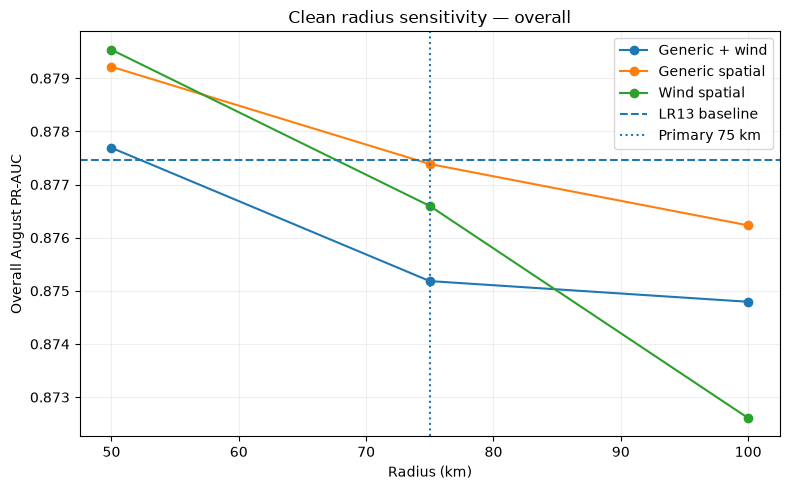

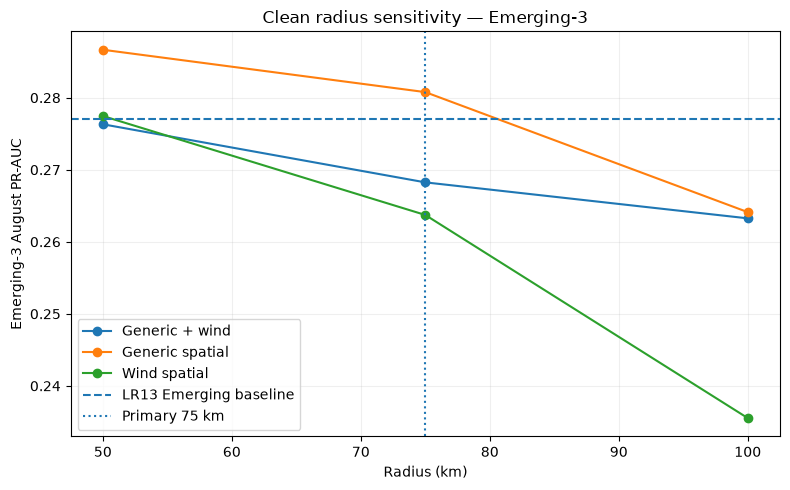

Saved:
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind_ablation\t2\figures\01_clean_radius_overall.png
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind_ablation\t2\figures\02_clean_radius_emerging.png


In [18]:
# 17. Radius sensitivity plots

fig, ax = plt.subplots(
    figsize=(8, 5)
)

for model_name, subset in radius_sensitivity.groupby(
    "Spatial model"
):
    ax.plot(
        subset["Radius km"],
        subset["Overall PR-AUC"],
        marker="o",
        label=model_name,
    )

ax.axhline(
    pr_lookup[BASE],
    linestyle="--",
    label="LR13 baseline",
)

ax.axvline(
    PRIMARY_RADIUS_KM,
    linestyle=":",
    label="Primary 75 km",
)

ax.set_xlabel("Radius (km)")
ax.set_ylabel("Overall August PR-AUC")
ax.set_title("Clean radius sensitivity — overall")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

overall_fig = (
    FIGURES_DIR
    / "01_clean_radius_overall.png"
)

plt.savefig(
    overall_fig,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

fig, ax = plt.subplots(
    figsize=(8, 5)
)

for model_name, subset in radius_sensitivity.groupby(
    "Spatial model"
):
    ax.plot(
        subset["Radius km"],
        subset["Emerging-3 PR-AUC"],
        marker="o",
        label=model_name,
    )

ax.axhline(
    emerging_lookup[BASE],
    linestyle="--",
    label="LR13 Emerging baseline",
)

ax.axvline(
    PRIMARY_RADIUS_KM,
    linestyle=":",
    label="Primary 75 km",
)

ax.set_xlabel("Radius (km)")
ax.set_ylabel("Emerging-3 August PR-AUC")
ax.set_title("Clean radius sensitivity — Emerging-3")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

emerging_fig = (
    FIGURES_DIR
    / "02_clean_radius_emerging.png"
)

plt.savefig(
    emerging_fig,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print("Saved:")
print("-", overall_fig)
print("-", emerging_fig)

# PART E — Spatial coefficient diagnostics

Because every model uses standardized features inside the logistic-regression pipeline,
the LR coefficients can be compared directionally within a model.

These coefficients are **not causal effects**.

In [19]:
# 18. Standardized spatial coefficients at the primary 75 km radius

coef_rows = []

for model_name in [
    GEN,
    WND,
    GEN_WND,
]:

    model = models[model_name]

    if model_name == GEN:
        features = LR17_GENERIC
    elif model_name == WND:
        features = LR17_WIND
    else:
        features = LR21_GENERIC_WIND

    coef = model.named_steps["lr"].coef_[0]

    for feature, value in zip(
        features,
        coef,
    ):
        if (
            feature in GENERIC_SPATIAL
            or feature in WIND_SPATIAL
        ):
            coef_rows.append({
                "Model": model_name,
                "Feature": feature,
                "Standardized LR coefficient": float(value),
            })

spatial_coefficients = pd.DataFrame(
    coef_rows
)

display(
    spatial_coefficients.sort_values(
        [
            "Model",
            "Standardized LR coefficient",
        ],
        ascending=[
            True,
            False,
        ],
    )
)

,Model,Feature,Standardized LR coefficient
0,LR17-G — LR13 + generic spatial,nbr_active_fraction_t,0.353261
1,LR17-G — LR13 + generic spatial,nbr_active_any_t,0.221195
3,LR17-G — LR13 + generic spatial,nbr_distw_frp_log1p_t,0.131438
2,LR17-G — LR13 + generic spatial,nbr_distw_fire_count_log1p_t,0.013766
7,LR17-W — LR13 + wind spatial,upwind_active_windspeed_exposure_t,0.251626
6,LR17-W — LR13 + wind spatial,upwind_frp_exposure_log1p_t,0.190535
4,LR17-W — LR13 + wind spatial,upwind_active_exposure_t,0.120738
5,LR17-W — LR13 + wind spatial,upwind_fire_count_exposure_log1p_t,-0.168789
8,LR21-GW — LR13 + generic + wind,nbr_active_fraction_t,0.325244
9,LR21-GW — LR13 + generic + wind,nbr_active_any_t,0.227848


# PART F — Save development-stage artifacts

September remains sealed.

In [20]:
# 19. Save tables

paths = {
    "overall": EXPORT_DIR / "overall_clean_ablation.csv",
    "deltas": EXPORT_DIR / "overall_clean_deltas.csv",
    "subgroups": EXPORT_DIR / "subgroup_clean_ablation.csv",
    "emerging_deltas": EXPORT_DIR / "emerging_clean_deltas.csv",
    "event_recall": EXPORT_DIR / "event_recall_clean_ablation.csv",
    "radius": EXPORT_DIR / "radius_sensitivity_clean_ablation.csv",
    "coefficients": EXPORT_DIR / "spatial_coefficients.csv",
    "edges": EXPORT_DIR / "edges_primary_75km.csv",
}

overall_results.to_csv(
    paths["overall"],
    index=False,
)

clean_deltas.to_csv(
    paths["deltas"],
    index=False,
)

subgroup_results.to_csv(
    paths["subgroups"],
    index=False,
)

emerging_deltas.to_csv(
    paths["emerging_deltas"],
    index=False,
)

event_recall.to_csv(
    paths["event_recall"],
    index=False,
)

radius_sensitivity.to_csv(
    paths["radius"],
    index=False,
)

spatial_coefficients.to_csv(
    paths["coefficients"],
    index=False,
)

edges_75.to_csv(
    paths["edges"],
    index=False,
)

print("Saved:")
for path in paths.values():
    print("-", path)

Saved:
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind_ablation\t2\exports\overall_clean_ablation.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind_ablation\t2\exports\overall_clean_deltas.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind_ablation\t2\exports\subgroup_clean_ablation.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind_ablation\t2\exports\emerging_clean_deltas.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind_ablation\t2\exports\event_recall_clean_ablation.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind_ablation\t2\exports\radius_sensitivity_clean_ablation.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind_ablation\t2\exports\spatial_coefficients.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind_abla

In [21]:
# 20. Save methodology metadata

metadata = {
    "notebook": "19B_clean_spatial_wind_ablation",
    "locked_region_id": LOCKED_REGION_ID,
    "nodes": int(N_NODES),
    "primary_radius_km": float(PRIMARY_RADIUS_KM),
    "sensitivity_radii_km": [
        float(x)
        for x in SENSITIVITY_RADII_KM
    ],
    "models": {
        "LR13": LR13_LOCAL,
        "LR17-G": LR17_GENERIC,
        "LR17-W": LR17_WIND,
        "LR21-GW": LR21_GENERIC_WIND,
        "LR23-WX-reference": LR23_WEATHER_REFERENCE,
    },
    "timing": {
        "local_fire": "day t",
        "neighbor_fire": "day t",
        "weather_wind": "day t",
        "target": "day t+1",
    },
    "selection": {
        "region_uses_emerging3": False,
        "region_uses_august": False,
        "region_uses_september": False,
    },
    "validation_period": [
        "2026-08-01",
        "2026-08-31",
    ],
    "september_evaluated": False,
}

metadata_path = (
    EXPORT_DIR
    / "nb19b_methodology_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("Saved:", metadata_path)

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\regional_025_spatial_wind_ablation\t2\exports\nb19b_methodology_metadata.json


In [22]:
# 21. Final automatic summary

emerging_table = (
    subgroup_results[
        subgroup_results["Context"].eq(
            "Emerging-3 eligible"
        )
    ]
    .sort_values(
        "PR-AUC",
        ascending=False,
    )
)

persistent_table = (
    subgroup_results[
        subgroup_results["Context"].eq(
            "Persistent-context"
        )
    ]
    .sort_values(
        "PR-AUC",
        ascending=False,
    )
)

print("=== Notebook 19B — Clean Spatial / Wind Ablation ===")
print()

print("DOMAIN")
print("Region                  :", LOCKED_REGION_ID)
print("Nodes                   :", N_NODES)
print("Primary radius          :", PRIMARY_RADIUS_KM, "km")
print("Directed edges          :", len(edges_75))
print("September               : SEALED")
print()

print("OVERALL AUGUST")
display(
    overall_results[
        [
            "Model",
            "Features",
            "PR-AUC",
            "ROC-AUC",
            "Precision",
            "Recall",
            "F1",
            "Brier",
        ]
    ]
)

print("CLEAN DELTAS VS LR13")
display(clean_deltas)

print("EMERGING-3 ELIGIBLE")
display(
    emerging_table[
        [
            "Model",
            "Rows",
            "Positives",
            "Prevalence",
            "PR-AUC",
            "Recall@0.5",
            "Precision@0.5",
        ]
    ]
)

print("EMERGING DELTAS VS LR13")
display(emerging_deltas)

print("PERSISTENT CONTEXT")
display(
    persistent_table[
        [
            "Model",
            "Rows",
            "Positives",
            "Prevalence",
            "PR-AUC",
        ]
    ]
)

print("RADIUS SENSITIVITY")
display(radius_sensitivity)

print()
print(
    "Decision rule for NB20: graph models are methodologically justified as a "
    "representation experiment if spatial features show stable added information "
    "or if we explicitly test whether learned message passing can recover spatial "
    "signal that handcrafted aggregation misses. Do not use September for this decision."
)

=== Notebook 19B — Clean Spatial / Wind Ablation ===

DOMAIN
Region                  : T2
Nodes                   : 133
Primary radius          : 75.0 km
Directed edges          : 2152
September               : SEALED

OVERALL AUGUST


,Model,Features,PR-AUC,ROC-AUC,Precision,Recall,F1,Brier
0,LR13 — Local current fire + history,13,0.877455,0.858476,0.707635,0.875980,0.782859,0.196675
1,LR17-G — LR13 + generic spatial,17,0.877386,0.854091,0.566622,0.978331,0.717619,0.300489
2,LR17-W — LR13 + wind spatial,17,0.876597,0.852600,0.608168,0.947441,0.740807,0.250780
3,LR23-WX — LR13 + same-cell weather (reference),23,0.876138,0.849698,0.574287,0.965883,0.720303,0.261741
4,LR21-GW — LR13 + generic + wind,21,0.875184,0.851414,0.566881,0.976948,0.717454,0.298057


CLEAN DELTAS VS LR13


,Question,Delta PR-AUC
0,Generic spatial beyond LR13,-0.000069
1,Wind spatial beyond LR13,-0.000858
2,Generic + wind beyond LR13,-0.002271
3,Wind beyond generic spatial,-0.002202
4,Same-cell weather beyond LR13 (reference),-0.001317


EMERGING-3 ELIGIBLE


,Model,Rows,Positives,Prevalence,PR-AUC,Recall@0.5,Precision@0.5
2,LR17-G — LR13 + generic spatial,1241,224,0.1805,0.280780,0.834821,0.201292
0,LR13 — Local current fire + history,1241,224,0.1805,0.277072,0.147321,0.370787
6,LR21-GW — LR13 + generic + wind,1241,224,0.1805,0.268251,0.821429,0.199566
4,LR17-W — LR13 + wind spatial,1241,224,0.1805,0.263726,0.616071,0.224026
8,LR23-WX — LR13 + same-cell weather (reference),1241,224,0.1805,0.229095,0.750000,0.201439


... (3 outputs left out)

,Model,Rows,Positives,Prevalence,PR-AUC
9,LR23-WX — LR13 + same-cell weather (reference),2882,1945,0.674879,0.909572
3,LR17-G — LR13 + generic spatial,2882,1945,0.674879,0.909154
1,LR13 — Local current fire + history,2882,1945,0.674879,0.909001
5,LR17-W — LR13 + wind spatial,2882,1945,0.674879,0.908372
7,LR21-GW — LR13 + generic + wind,2882,1945,0.674879,0.907284


RADIUS SENSITIVITY


,Radius km,Spatial model,Directed edges,Mean degree,Overall PR-AUC,Emerging-3 PR-AUC,Primary radius
0,50.0,Generic spatial,922,6.932331,0.879217,0.286662,False
1,50.0,Wind spatial,922,6.932331,0.879536,0.277465,False
2,50.0,Generic + wind,922,6.932331,0.877691,0.276317,False
3,75.0,Generic spatial,2152,16.180451,0.877386,0.280780,True
4,75.0,Wind spatial,2152,16.180451,0.876597,0.263726,True
5,75.0,Generic + wind,2152,16.180451,0.875184,0.268251,True
6,100.0,Generic spatial,3612,27.157895,0.876232,0.264120,False
7,100.0,Wind spatial,3612,27.157895,0.872607,0.235529,False
8,100.0,Generic + wind,3612,27.157895,0.874795,0.263257,False



Decision rule for NB20: graph models are methodologically justified as a representation experiment if spatial features show stable added information or if we explicitly test whether learned message passing can recover spatial signal that handcrafted aggregation misses. Do not use September for this decision.


# What to send for review

After **Run All**, send:

1. Section 11 — clean overall model table
2. Section 12 — clean deltas vs LR13
3. Section 13 — subgroup table
4. Section 14 — Emerging deltas vs LR13
5. Section 16 — radius sensitivity
6. Section 18 — spatial coefficients
7. Section 21 — final summary

Do **not** inspect September.